# Team 22 — Feature Engineering & Hypothesis Validation

Рабочий notebook: сначала проверяет согласованный поток из `spec.md` (S0–S4 и выбор импутации задержек), затем отдельно оценивает дополнительные гипотезы. Все обучаемые преобразования выполняются внутри `Pipeline`/`ColumnTransformer`; CV и диагностические графики используют только `X_train`. Тестовая выборка используется только в последней ячейке.

In [1]:
from pathlib import Path
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PowerTransformer, RobustScaler, FunctionTransformer

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "data" / "raw" / "airline_passenger_satisfaction.csv").exists() and (ROOT.parent / "data" / "raw" / "airline_passenger_satisfaction.csv").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from airline_fe.config import (
    AGE, CLASS_ORDER, DELAY_PAIR, ID_COL, LIKERT, NOMINAL, ORDINAL,
    RANDOM_STATE, SKEWED, TARGET,
)
from airline_fe.transformers import DelayFeatureEngineer, LikertZeroFlagger
from airline_fe.transformers_upgraded import (
    AgeBinner, DelayOccurrenceFlagger, FlightDistanceSpline,
    LikertLevelEncoder, ServiceRatingSummary, TravelClassInteraction,
)

DATA_PATH = ROOT / "data" / "raw" / "airline_passenger_satisfaction.csv"
assert DATA_PATH.exists(), f"CSV not found: {DATA_PATH}"
print("Repository root:", ROOT)
print("Dataset:", DATA_PATH)

Repository root: /Users/alisertoksanbaev/Desktop/kbtu1.1/machine learning KBTU/MLproject/ML-project
Dataset: /Users/alisertoksanbaev/Desktop/kbtu1.1/machine learning KBTU/MLproject/ML-project/airline_passenger_satisfaction.csv


## 1. Load data and split first
Drop the identifier and map the target, then split immediately. The assertions below validate the raw schema and allowed domains; all distributional calculations and model fitting are done only on `X_train`.

In [2]:
df = pd.read_csv(DATA_PATH)
assert df.shape == (129_880, 24), f"Unexpected dataset shape: {df.shape}"
assert df.columns[0] == ID_COL and df.columns[-1] == TARGET

X = df.drop(columns=[ID_COL, TARGET])
y = df[TARGET].map({"Satisfied": 1, "Neutral or Dissatisfied": 0})
assert y.notna().all(), "Unexpected target label."
y = y.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
assert X_train.shape == (103_904, 22)
assert X_test.shape == (25_976, 22)
expected_features = ["Gender", "Age", "Customer Type", "Type of Travel", "Class", "Flight Distance", "Departure Delay", "Arrival Delay"] + LIKERT
assert list(X_train.columns) == expected_features, "Unexpected feature schema/order."
print(f"Train: {X_train.shape}; test: {X_test.shape}")
print("Train target proportions:", y_train.value_counts(normalize=True).sort_index().round(4).to_dict())

Train: (103904, 22); test: (25976, 22)
Train target proportions: {0: 0.5655, 1: 0.4345}


,min,median,max,missing,skew,zero_pct
Age,7.0,40.0,85.0,0,-0.000,0.000
Flight Distance,31.0,844.0,4983.0,0,1.109,0.000
Departure Delay,0.0,0.0,1592.0,0,6.832,56.478
Arrival Delay,0.0,0.0,1584.0,321,6.700,56.044
Departure and Arrival Time Convenience,0.0,3.0,5.0,0,-0.335,5.175
Ease of Online Booking,0.0,3.0,5.0,0,-0.023,4.367
Check-in Service,1.0,3.0,5.0,0,-0.365,0.000
Online Boarding,0.0,3.0,5.0,0,-0.458,2.388
Gate Location,1.0,3.0,5.0,0,-0.062,0.000
On-board Service,0.0,4.0,5.0,0,-0.422,0.003


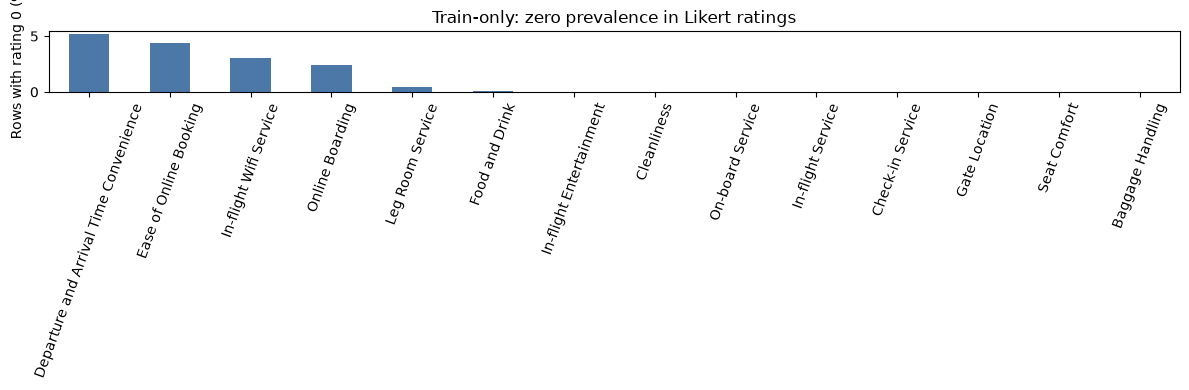

In [3]:
# Train-only diagnostic profile
numeric_profile = X_train.select_dtypes(include="number").agg(["min", "median", "max"]).T
numeric_profile["missing"] = X_train.select_dtypes(include="number").isna().sum()
numeric_profile["skew"] = X_train.select_dtypes(include="number").skew()
numeric_profile["zero_pct"] = X_train.select_dtypes(include="number").eq(0).mean().mul(100)
display(numeric_profile.round(3))

likert_zero_pct = X_train[LIKERT].eq(0).mean().mul(100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 4))
likert_zero_pct.plot.bar(ax=ax, color="#4C78A8")
ax.set(title="Train-only: zero prevalence in Likert ratings", ylabel="Rows with rating 0 (%)")
ax.tick_params(axis="x", rotation=70)
plt.tight_layout()

## 2. EDA evidence for the agreed engineering flow
These plots motivate the required transformations. They are descriptive evidence, not proof of predictive benefit; that is measured using the paired CV comparisons below.

Train arrival-delay missing: 321
Train delay correlation: 0.9659


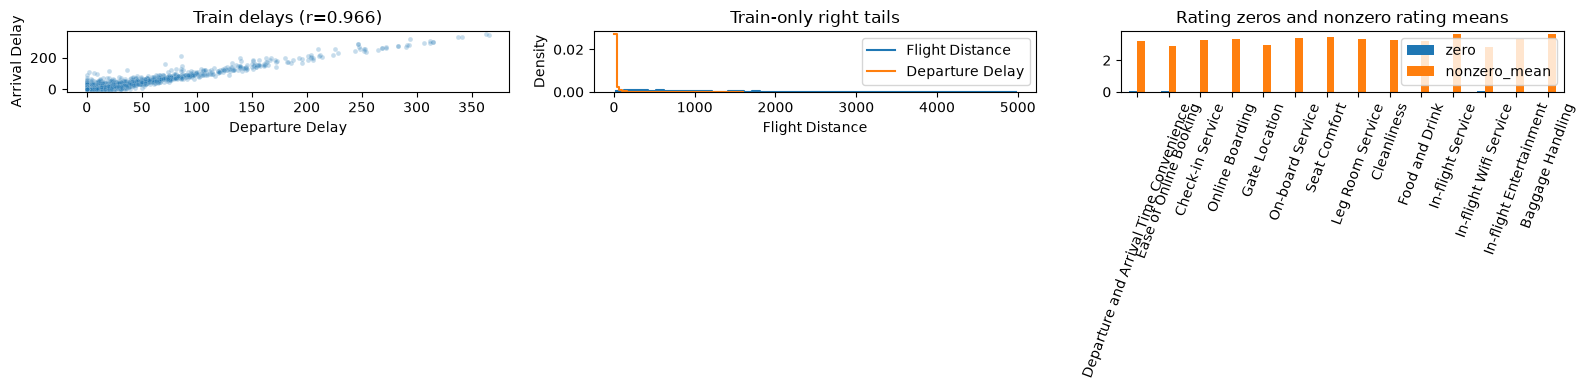

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
train_delay = X_train[DELAY_PAIR].copy()
sns.scatterplot(data=train_delay.sample(min(5000, len(train_delay)), random_state=RANDOM_STATE), x=DELAY_PAIR[0], y=DELAY_PAIR[1], alpha=.25, s=12, ax=axes[0])
axes[0].set_title(f"Train delays (r={train_delay.corr().iloc[0,1]:.3f})")
for col in ["Flight Distance", "Departure Delay"]:
    sns.histplot(X_train[col], bins=50, stat="density", element="step", fill=False, label=col, ax=axes[1])
axes[1].set_title("Train-only right tails"); axes[1].legend()
zero_means = pd.DataFrame({"zero": X_train[LIKERT].eq(0).mean(), "nonzero_mean": X_train[LIKERT].where(X_train[LIKERT].ne(0)).mean()})
zero_means.plot.bar(ax=axes[2])
axes[2].set_title("Rating zeros and nonzero rating means"); axes[2].tick_params(axis="x", rotation=70)
plt.tight_layout()

print("Train arrival-delay missing:", int(X_train["Arrival Delay"].isna().sum()))
print("Train delay correlation:", round(train_delay.corr().iloc[0, 1], 4))

## 3. Pipeline builder for ablations
S0–S4 follow `spec.md`. S1b is the specified alternative arrival-median imputation. Every imputer, encoder, scaler, custom transformer, and variance filter is fit by the pipeline inside each CV fold.

In [5]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": make_scorer(f1_score)}


def numeric_pipe(log=False):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if log:
        steps.append(("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
    steps.append(("scale", RobustScaler()))
    return Pipeline(steps)


def build_preprocessor(step="S4", impute_strategy="net_median", hypothesis=None):
    delay_mode = "raw" if step == "S0" else "net"
    do_log = step in {"S2", "S3", "S4"}
    flag_mode = {"S0": "none", "S1": "none", "S1b": "none", "S2": "none", "S3": "all", "S4": "nzv"}.get(step)
    if flag_mode is None:
        raise ValueError(f"Unknown canonical step: {step}")

    # Upgraded hypotheses apply on top of final canonical S4; specific candidates replace
    # the relevant canonical branch where necessary rather than changing unrelated steps.
    h = hypothesis
    age_transform = numeric_pipe()
    if h == "age_bins":
        age_transform = Pipeline([("impute", SimpleImputer(strategy="median")), ("bands", AgeBinner())])

    distance_transform = numeric_pipe(log=True)
    if h == "flight_distance_spline":
        distance_transform = Pipeline([("impute", SimpleImputer(strategy="median")), ("spline", FlightDistanceSpline()), ("scale", RobustScaler())])

    likert_transform = numeric_pipe()
    if h == "likert_nonlinearity":
        likert_transform = LikertLevelEncoder()

    branches = [
        ("nominal", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), NOMINAL),
        ("class_ord", OrdinalEncoder(categories=CLASS_ORDER, handle_unknown="use_encoded_value", unknown_value=-1), ORDINAL),
        ("age", age_transform, AGE),
        ("distance", distance_transform, ["Flight Distance"]),
    ]
    # Keep departure delay's canonical log1p branch, independent of the net-delay feature.
    branches.append(("departure_delay", numeric_pipe(log=do_log), ["Departure Delay"]))
    if delay_mode == "raw":
        branches.append(("arrival_raw", numeric_pipe(), ["Arrival Delay"]))
    else:
        branches.append(("net_delay", Pipeline([
            ("engineer", DelayFeatureEngineer(impute_strategy=impute_strategy)),
            ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
            ("scale", RobustScaler()),
        ]), DELAY_PAIR))
    branches.append(("likert", likert_transform, LIKERT))
    if flag_mode != "none":
        flag_steps = [("flag", LikertZeroFlagger())]
        if flag_mode == "nzv":
            flag_steps.append(("variance", VarianceThreshold(0.0099)))
        branches.append(("likert_flags", Pipeline(flag_steps), LIKERT))

    if h == "delay_occurrence":
        branches.append(("delay_occurrence", Pipeline([
            ("impute", SimpleImputer(strategy="median")), ("occurrence", DelayOccurrenceFlagger())
        ]), DELAY_PAIR))
    if h == "travel_class_interaction":
        branches.append(("travel_class_interaction", TravelClassInteraction(), ["Type of Travel", "Class"]))
    if h == "service_summary":
        branches.append(("service_summary", ServiceRatingSummary(), LIKERT))

    return ColumnTransformer(branches, remainder="drop", verbose_feature_names_out=False)


def build_model(step="S4", impute_strategy="net_median", hypothesis=None):
    return Pipeline([
        ("preprocess", build_preprocessor(step, impute_strategy, hypothesis)),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])


def score_cv(name, estimator):
    result = cross_validate(estimator, X_train, y_train, cv=CV, scoring=SCORING,
                            return_train_score=True, n_jobs=-1, error_score="raise")
    row = {"variant": name}
    for metric in SCORING:
        vals = result[f"test_{metric}"]
        row[f"{metric}_mean"] = vals.mean()
        row[f"{metric}_std"] = vals.std(ddof=1)
        row[f"{metric}_folds"] = vals
    row["fit_time_mean_s"] = result["fit_time"].mean()
    row["train_roc_auc_mean"] = result["train_roc_auc"].mean()
    return row


def plot_cv_comparison(rows, title):
    table = pd.DataFrame([{k: v for k, v in r.items() if not k.endswith("_folds")} for r in rows])
    display(table.round(4))
    metrics = ["roc_auc", "pr_auc", "f1"]
    fig, ax = plt.subplots(figsize=(max(7, 1.25 * len(rows)), 4))
    x = np.arange(len(rows)); width = .24
    for j, metric in enumerate(metrics):
        means = [r[f"{metric}_mean"] for r in rows]
        stds = [r[f"{metric}_std"] for r in rows]
        ax.bar(x + (j - 1) * width, means, width, yerr=stds, capsize=3, label=metric.upper())
    ax.set_xticks(x, [r["variant"] for r in rows], rotation=25, ha="right")
    ax.set_ylim(0, 1); ax.set_ylabel("5-fold CV score (mean ± SD)"); ax.set_title(title); ax.legend()
    plt.tight_layout()
    return table

## 4. Agreed flow: S0–S4 and imputation comparison
The table and score plot after this cell report fold-averaged CV metrics. For each transition, interpret changes against paired fold variability, not just the raw mean.

,variant,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,fit_time_mean_s,train_roc_auc_mean
0,S0,0.9256,0.0019,0.9300,0.0018,0.8515,0.0033,0.4551,0.9257
1,S1,0.9255,0.0019,0.9300,0.0018,0.8514,0.0032,0.4388,0.9256
2,S2,0.9265,0.0018,0.9305,0.0017,0.8516,0.0034,0.4578,0.9266
3,S3,0.9648,0.0004,0.9576,0.0005,0.8875,0.0018,1.1877,0.9648
4,S4,0.9646,0.0004,0.9572,0.0004,0.8876,0.0019,0.7370,0.9647
5,S1b_arrival_median,0.9256,0.0019,0.9300,0.0018,0.8515,0.0034,0.5078,0.9257


,variant,delta_roc_auc_vs_S0,paired_delta_sd
0,S0,0.00000,0.00000
1,S1,-0.00007,0.00004
2,S2,0.00088,0.00018
3,S3,0.03915,0.00153
4,S4,0.03901,0.00153
5,S1b_arrival_median,-0.00002,0.00001


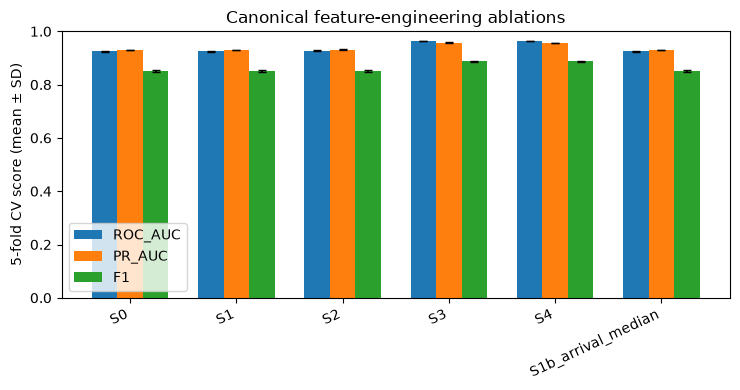

In [6]:
canonical_rows = []
for step in ["S0", "S1", "S2", "S3", "S4"]:
    strategy = "net_median"
    canonical_rows.append(score_cv(step, build_model(step=step, impute_strategy=strategy)))
canonical_rows.append(score_cv("S1b_arrival_median", build_model(step="S1", impute_strategy="arrival_median")))
canonical_table = plot_cv_comparison(canonical_rows, "Canonical feature-engineering ablations")

# Paired fold deltas vs S0, using the exact same outer folds.
base = next(row for row in canonical_rows if row["variant"] == "S0")
paired = []
for row in canonical_rows:
    deltas = row["roc_auc_folds"] - base["roc_auc_folds"]
    paired.append({"variant": row["variant"], "delta_roc_auc_vs_S0": deltas.mean(),
                   "paired_delta_sd": deltas.std(ddof=1)})
display(pd.DataFrame(paired).round(5))

## 5. Extra hypotheses layered on canonical S4
Each candidate is compared to the S4 canonical pipeline using the same five folds. The preceding EDA plots provide feature-level motivation; each hypothesis below also gets its own CV comparison chart. An expected-effectivity value is a prior ranking only; the CV delta is the empirical result.

,variant,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,fit_time_mean_s,train_roc_auc_mean
0,S4_baseline,0.9646,0.0004,0.9572,0.0004,0.8876,0.0019,0.7750,0.9647
1,delay_occurrence,0.9649,0.0004,0.9574,0.0004,0.8878,0.0025,0.8558,0.9649


,variant,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,fit_time_mean_s,train_roc_auc_mean
0,S4_baseline,0.9646,0.0004,0.9572,0.0004,0.8876,0.0019,0.7750,0.9647
1,travel_class_interaction,0.9650,0.0004,0.9574,0.0005,0.8884,0.0022,1.0216,0.9651


,variant,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,fit_time_mean_s,train_roc_auc_mean
0,S4_baseline,0.9646,0.0004,0.9572,0.0004,0.8876,0.0019,0.7750,0.9647
1,service_summary,0.9646,0.0004,0.9571,0.0003,0.8876,0.0019,1.8374,0.9647


,variant,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,fit_time_mean_s,train_roc_auc_mean
0,S4_baseline,0.9646,0.0004,0.9572,0.0004,0.8876,0.0019,0.7750,0.9647
1,likert_nonlinearity,0.9790,0.0004,0.9750,0.0008,0.9222,0.0014,1.7711,0.9792


,variant,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,fit_time_mean_s,train_roc_auc_mean
0,S4_baseline,0.9646,0.0004,0.9572,0.0004,0.8876,0.0019,0.7750,0.9647
1,flight_distance_spline,0.9647,0.0004,0.9572,0.0004,0.8872,0.0021,2.6958,0.9647


,variant,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,fit_time_mean_s,train_roc_auc_mean
0,S4_baseline,0.9646,0.0004,0.9572,0.0004,0.8876,0.0019,0.7750,0.9647
1,age_bins,0.9651,0.0004,0.9577,0.0005,0.8878,0.0017,0.8027,0.9651


,variant,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,fit_time_mean_s,train_roc_auc_mean
0,S4_baseline,0.9646,0.0004,0.9572,0.0004,0.8876,0.0019,0.7750,0.9647
1,delay_occurrence,0.9649,0.0004,0.9574,0.0004,0.8878,0.0025,0.8558,0.9649
2,travel_class_interaction,0.9650,0.0004,0.9574,0.0005,0.8884,0.0022,1.0216,0.9651
3,service_summary,0.9646,0.0004,0.9571,0.0003,0.8876,0.0019,1.8374,0.9647
4,likert_nonlinearity,0.9790,0.0004,0.9750,0.0008,0.9222,0.0014,1.7711,0.9792
5,flight_distance_spline,0.9647,0.0004,0.9572,0.0004,0.8872,0.0021,2.6958,0.9647
6,age_bins,0.9651,0.0004,0.9577,0.0005,0.8878,0.0017,0.8027,0.9651


,hypothesis,delta_roc_auc_mean,paired_delta_sd,delta_pr_auc_mean,delta_f1_mean,fit_time_mean_s,supported_beyond_fold_noise
0,delay_occurrence,0.00022,0.00009,0.00025,0.00021,0.85578,True
1,travel_class_interaction,0.00035,0.00010,0.00026,0.00076,1.02156,True
2,service_summary,-0.00002,0.00002,-0.00007,-0.00005,1.83740,False
3,likert_nonlinearity,0.01435,0.00062,0.01784,0.03460,1.77113,True
4,flight_distance_spline,0.00003,0.00004,0.00003,-0.00042,2.69577,False
5,age_bins,0.00042,0.00010,0.00058,0.00018,0.80269,True


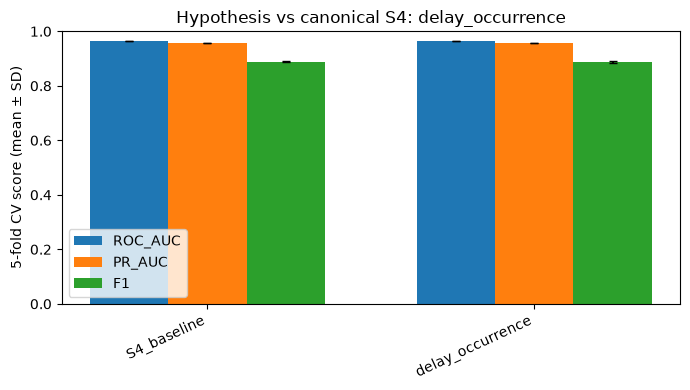

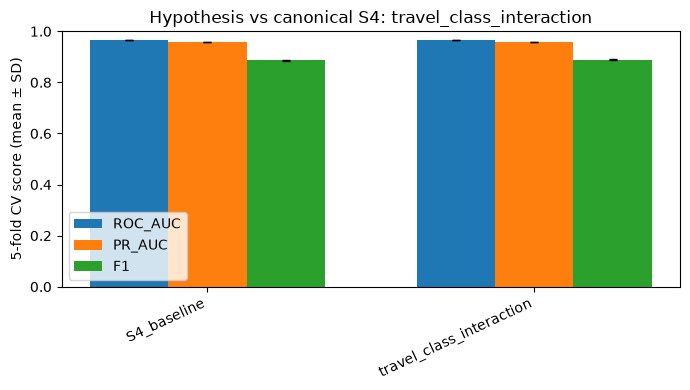

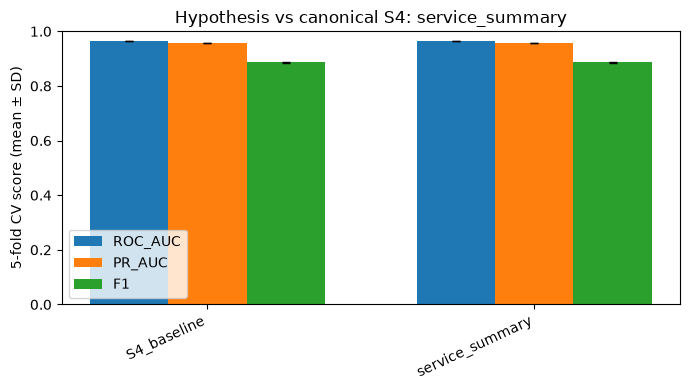

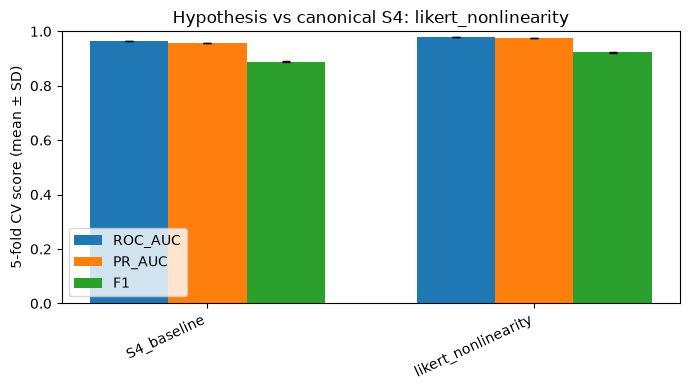

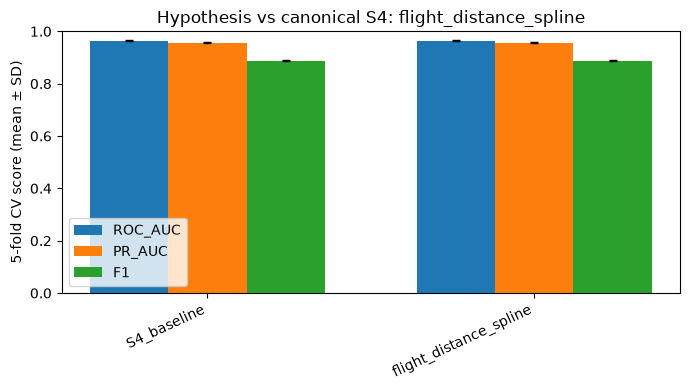

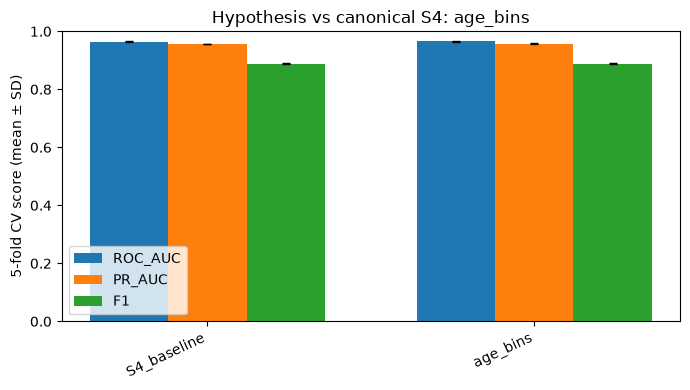

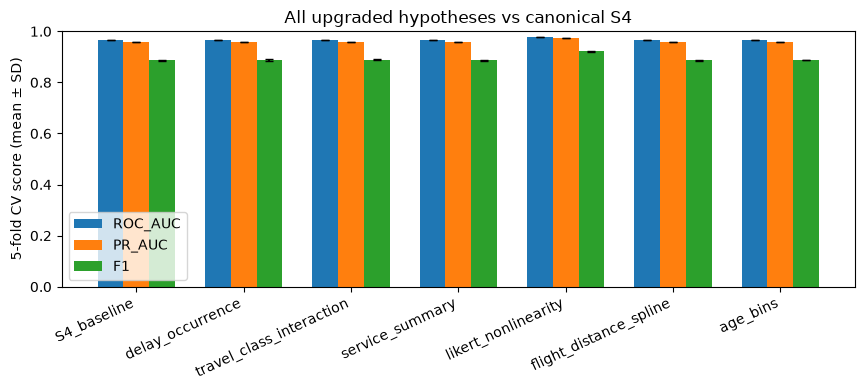

In [7]:
hypothesis_rows = [score_cv("S4_baseline", build_model(step="S4"))]
for hypothesis in [
    "delay_occurrence",
    "travel_class_interaction",
    "service_summary",
    "likert_nonlinearity",
    "flight_distance_spline",
    "age_bins",
]:
    candidate = score_cv(hypothesis, build_model(step="S4", hypothesis=hypothesis))
    hypothesis_rows.append(candidate)
    plot_cv_comparison([hypothesis_rows[0], candidate], f"Hypothesis vs canonical S4: {hypothesis}")

hypothesis_table = plot_cv_comparison(hypothesis_rows, "All upgraded hypotheses vs canonical S4")
base_row = hypothesis_rows[0]
empirical = []
for row in hypothesis_rows[1:]:
    delta = row["roc_auc_folds"] - base_row["roc_auc_folds"]
    empirical.append({
        "hypothesis": row["variant"],
        "delta_roc_auc_mean": delta.mean(),
        "paired_delta_sd": delta.std(ddof=1),
        "delta_pr_auc_mean": (row["pr_auc_folds"] - base_row["pr_auc_folds"]).mean(),
        "delta_f1_mean": (row["f1_folds"] - base_row["f1_folds"]).mean(),
        "fit_time_mean_s": row["fit_time_mean_s"],
        "supported_beyond_fold_noise": abs(delta.mean()) > delta.std(ddof=1),
    })
empirical_table = pd.DataFrame(empirical)
display(empirical_table.round(5))

### Interpreting effectiveness
Do not keep an upgrade just because its mean score is higher. Review paired ROC-AUC delta alongside paired fold SD, PR-AUC/F1, fit time, and feature-count increase. A small or unstable change is “no clear improvement”; prefer the simpler canonical S4 flow in that case.

## 6. Final sanity check
The final model is fitted on the training split and then evaluated once on the held-out test split. Do not use test metrics to revise feature engineering decisions.

In [8]:
final_pipe = build_model(step="S4")
final_pipe.fit(X_train, y_train)
X_train_transformed = final_pipe.named_steps["preprocess"].transform(X_train)
X_test_transformed = final_pipe.named_steps["preprocess"].transform(X_test)
y_pred = final_pipe.predict(X_test)
print("Raw shapes:", X_train.shape, X_test.shape)
print("Transformed shapes:", X_train_transformed.shape, X_test_transformed.shape)
print("Prediction shape:", y_pred.shape)
assert X_train_transformed.shape[1] == X_test_transformed.shape[1]
assert np.isfinite(np.asarray(X_train_transformed)).all()
assert np.isfinite(np.asarray(X_test_transformed)).all()

Raw shapes: (103904, 22) (25976, 22)
Transformed shapes: (103904, 26) (25976, 26)
Prediction shape: (25976,)
